# 第七课：趋势信号有效，还是只是少持仓？

第六课发现：趋势过滤降低历史回撤，同时减少收益、增加现金。第二阶段现在从“构建信号”进入“设计对照、审查证据”。本课不增加更复杂的预测器，而是检查已有信号究竟改变了什么。

**学习目标**：① 建立简单对照；② 区分总敞口与资产选择；③ 识别事后信息；④ 区分资金敞口相同、风险相同与有效alpha。

仍使用三ETF、同一快照、同一区间和原账本。只改变目标生成规则。规则先写在 `docs/07_research_design.md`；已有历史已被观察，不作样本外声明。

## 1. 五个方案分别回答什么问题？

| 名称 | 目标规则 | 用途与限制 |
|---|---|---|
| erc_126 | 原ERC，全额投入 | 延续前课基准 |
| trend_200 | ERC权重分别乘0/1信号 | 原趋势方案 |
| fixed_70 | 所有ERC权重乘70%，现金30% | 不择时的低敞口对照；70%是看过前课后选择的整数字例，并非独立验证参数 |
| dynamic_total | 所有ERC权重乘当期趋势总敞口 | 保留ERC相对比例，只调总投入；与趋势匹配月度总目标，不匹配风险 |
| matched_mean_POSTHOC | 所有ERC权重乘全样本趋势目标总敞口均值 | **事后诊断，不是当时可执行的历史规则** |

例如ERC是30/50/20，信号为1/0/1：趋势目标30/0/20，合计投入50%；dynamic_total则为15/25/10，也投入50%，但仍持有债券。fixed_70则为21/35/14。三者都有现金，却不是同一个组合。

“关闭哪些资产”和“合计投入多少”是两种决策。比较这些完整规则能帮助理解差异，但不构成严格的因果或可加总收益分解。

In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from market_data import load_snapshot
from risk_models import equal_risk_schedule
from signals import trend_filter_schedule
from controls import scale_schedule
from portfolio import simulate,reconcile
SNAPSHOT=os.environ.get('MARKET_LAB_SNAPSHOT','20261007T234808781424Z')
frames,manifest=load_snapshot(SNAPSHOT)
prices=pd.DataFrame({s:f['Adj Close'] for s,f in frames.items()});assets=list(prices.columns)
base,_=equal_risk_schedule(prices,126)
base=base.loc[[d for d in base.index if prices.index.get_loc(d)>=253]].copy()
trend,audit=trend_filter_schedule(prices,base,200)
e=trend[assets].sum(axis=1)
mean_e=float(e.mean())  # Explicitly uses full-sample future information.
schedules={'erc_126':base,'trend_200':trend,
    'fixed_70':scale_schedule(base,assets,.7),
    'dynamic_total':scale_schedule(base,assets,e),
    'matched_mean_POSTHOC':scale_schedule(base,assets,mean_e)}
START=base.index[0];trading={s:f.loc[START:].copy() for s,f in frames.items()}
OUT=ROOT/'reports'/('07_'+SNAPSHOT);OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
print('快照',SNAPSHOT,'；区间',START.date(),'至',prices.index[-1].date())
print('事后全样本月度目标平均敞口：',f'{mean_e:.2%}')
print('这不是第六课日均实际敞口1−29.60%，两者统计对象和频率不同。')
assert np.allclose(schedules['dynamic_total'][assets].sum(axis=1),e)
example=trend.index[(e>0)&(e<1-1e-10)][0]
show=pd.DataFrame({name:s.loc[example,assets].astype(float) for name,s in schedules.items()}).T
show['cash']=1-show.sum(axis=1)
print('同一次决策对应的执行日：',example.date())
display(show.style.format('{:.2%}'))

快照 20261007T234808781424Z ；区间 2011-02-01 至 2026-10-06
事后全样本月度目标平均敞口： 70.20%
这不是第六课日均实际敞口1−29.60%，两者统计对象和频率不同。
同一次决策对应的执行日： 2011-02-01


,SPY,IEF,GLD,cash
erc_126,32.93%,47.97%,19.10%,0.00%
trend_200,32.93%,0.00%,19.10%,47.97%
fixed_70,23.05%,33.58%,13.37%,30.00%
dynamic_total,17.13%,24.96%,9.94%,47.97%
matched_mean_POSTHOC,23.12%,33.68%,13.41%,29.80%


## 2. 先核对敞口是否真的匹配，再比较收益

月度目标敞口是三项ETF目标权重之和；日均实际敞口是每日持仓市值÷净值的时间平均。市场漂移、现金分红与调仓频率会使两者不同。

全样本平均目标对照只让“目标敞口的月度平均”相等，不让每天持仓相等。dynamic_total只在各月目标上匹配总投入，不能保证波动、相关性或持有期现金一样。

尤其注意：目标乘70%不等于策略收益、波动和最大回撤在真实账本中都精确乘70%；现金和再平衡改变了路径。

,mean_target_exposure,mean_actual_exposure,annual_volatility
erc_126,100.00%,99.98%,6.35%
trend_200,70.20%,70.40%,4.85%
fixed_70,70.00%,70.03%,4.44%
dynamic_total,70.20%,70.39%,4.53%
matched_mean_POSTHOC,70.20%,70.23%,4.45%


列：月均目标敞口／日均实际敞口／年化波动。资金敞口相近不是风险匹配。


,final_nav,cagr,max_drawdown
erc_126,"259,822.67",6.28%,-17.89%
trend_200,"206,037.48",4.72%,-10.86%
fixed_70,"196,452.25",4.40%,-12.80%
dynamic_total,"208,046.88",4.78%,-10.62%
matched_mean_POSTHOC,"196,822.68",4.41%,-12.84%


,fees_paid,trade_days,annual_gross_turnover
erc_126,768.04,189,0.61
trend_200,"2,461.02",184,2.13
fixed_70,463.96,189,0.43
dynamic_total,"2,195.13",184,1.93
matched_mean_POSTHOC,465.72,189,0.43


末表：费用美元／交易日数／年均双边换手倍数（含建仓，以前日净值归一化）。


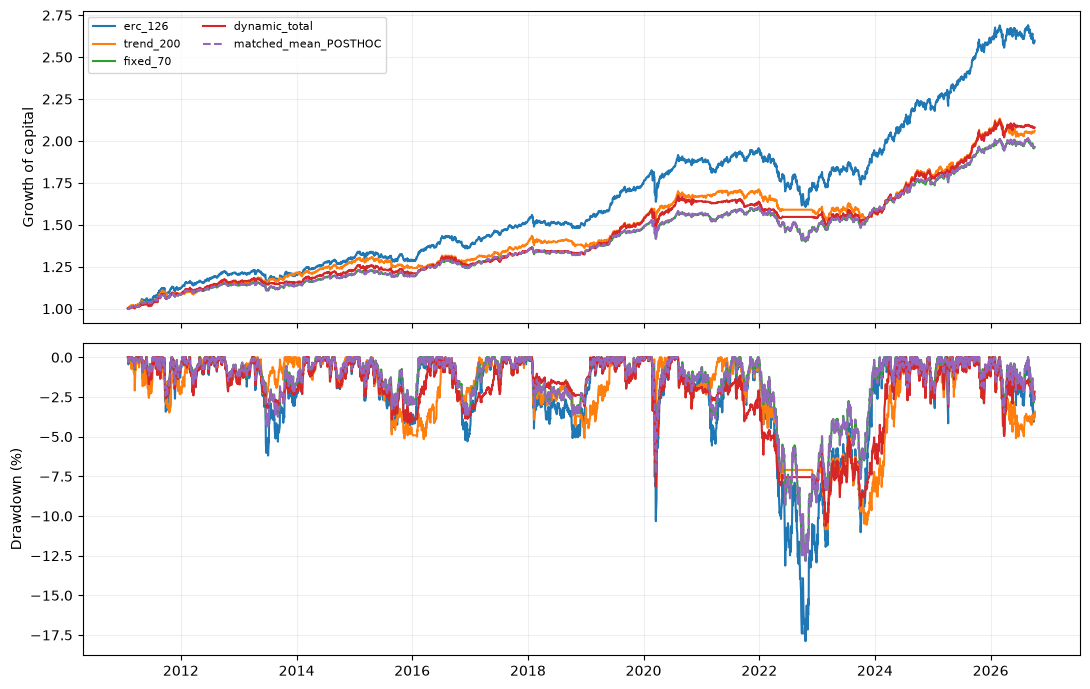

In [2]:
results={name:simulate(trading,s.iloc[0][assets].to_dict(),target_schedule=s) for name,s in schedules.items()}
metrics=pd.DataFrame({name:r.metrics() for name,r in results.items()}).T
metrics['mean_target_exposure']=[s[assets].sum(axis=1).mean() for s in schedules.values()]
metrics['mean_actual_exposure']=[(1-r.daily.cash/r.daily.nav).mean() for r in results.values()]
metrics['annual_gross_turnover']=[
    (r.trades.groupby('date').notional.apply(lambda x:x.abs().sum())/
     r.daily.nav.shift(1).fillna(r.initial_cash)).sum()/
    ((r.daily.index[-1]-r.daily.index[0]).days/365.25) for r in results.values()]
display(metrics[['mean_target_exposure','mean_actual_exposure','annual_volatility']].style.format('{:.2%}'))
print('列：月均目标敞口／日均实际敞口／年化波动。资金敞口相近不是风险匹配。')
display(metrics[['final_nav','cagr','max_drawdown']].style.format({'final_nav':'{:,.2f}','cagr':'{:.2%}','max_drawdown':'{:.2%}'}))
display(metrics[['fees_paid','trade_days','annual_gross_turnover']].style.format({'fees_paid':'{:,.2f}','trade_days':'{:.0f}','annual_gross_turnover':'{:.2f}'}))
print('末表：费用美元／交易日数／年均双边换手倍数（含建仓，以前日净值归一化）。')
metrics.to_csv(OUT/'metrics.csv')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for name,r in results.items():
    nav=r.daily.nav;peak=np.maximum.accumulate(np.r_[r.initial_cash,nav])[1:]
    style='--' if 'POSTHOC' in name else '-'
    axes[0].plot(nav.index,nav/r.initial_cash,ls=style,label=name)
    axes[1].plot(nav.index,(nav/peak-1)*100,ls=style)
axes[0].legend(fontsize=8,ncol=2);axes[0].set_ylabel('Growth of capital')
axes[1].set_ylabel('Drawdown (%)');fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=150);plt.show()

## 3. 总敞口与资产选择：为什么同样投入一半，结果仍不同？

趋势方案每月关闭特定资产，dynamic_total把全部资产一起等比例缩小。比较二者，可以观察同样月度总目标下，资产分配差异与相关交易如何影响结果；不能把净值差直接称作纯选股alpha或严格因果效应。

比较dynamic_total与固定比例，则观察动态总投入的整体效果；但动态缩仓仍使用趋势信息，且总风险与现金路径不匹配。不要把它称为“没有信号”的对照。

下图上半部分画月度目标，下半部分画实际现金。目标相同不等于实际持仓路径相同。事后平均线只是帮助诊断，不应进入实盘历史成绩表。

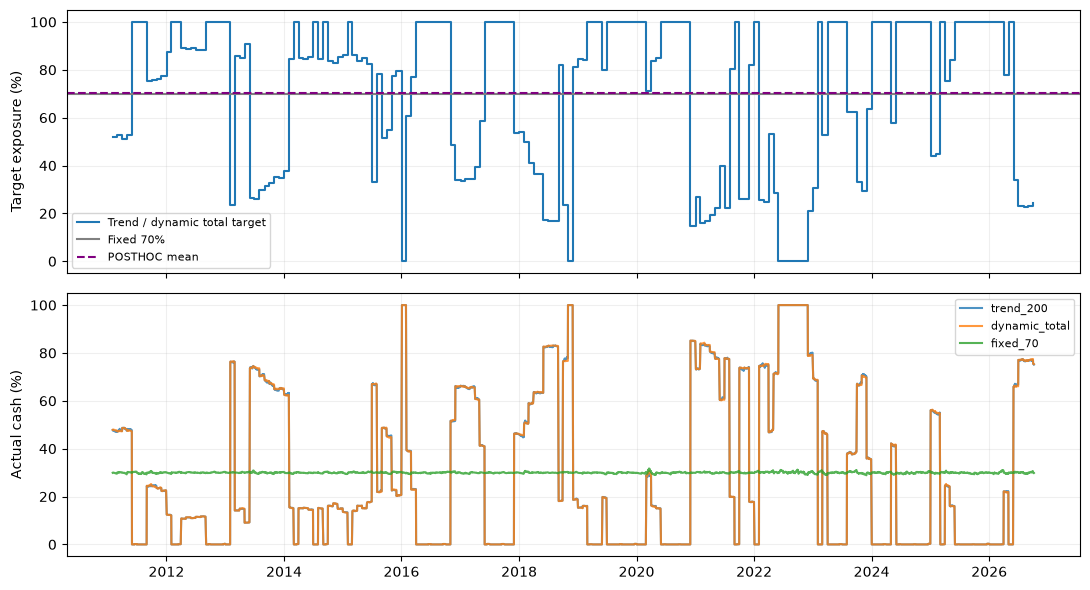

,cagr_difference_pp,drawdown_difference_pp,fee_difference
comparison,,,
trend_200 minus fixed_70,+0.32,+1.95,+1997.06
trend_200 minus dynamic_total,-0.06,-0.24,+265.89
dynamic_total minus matched_mean_POSTHOC,+0.37,+2.22,+1729.41


回撤差为正表示前者回撤较浅；收益差不是alpha估计，事后对照不具备当时可交易性。


In [3]:
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].step(e.index,e*100,where='post',label='Trend / dynamic total target')
axes[0].axhline(70,color='gray',label='Fixed 70%')
axes[0].axhline(mean_e*100,color='purple',ls='--',label='POSTHOC mean')
for name in ['trend_200','dynamic_total','fixed_70']:
    r=results[name];axes[1].plot(r.daily.index,r.daily.cash/r.daily.nav*100,label=name,alpha=.8)
axes[0].set_ylabel('Target exposure (%)');axes[1].set_ylabel('Actual cash (%)')
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'exposure.png',dpi=150);plt.show()
contrast=[]
for a,b in [('trend_200','fixed_70'),('trend_200','dynamic_total'),
            ('dynamic_total','matched_mean_POSTHOC')]:
    x,y=metrics.loc[a],metrics.loc[b]
    contrast.append(dict(comparison=a+' minus '+b,cagr_difference_pp=(x.cagr-y.cagr)*100,
        drawdown_difference_pp=(x.max_drawdown-y.max_drawdown)*100,fee_difference=x.fees_paid-y.fees_paid))
contrasts=pd.DataFrame(contrast).set_index('comparison')
display(contrasts.style.format('{:+.2f}'));contrasts.to_csv(OUT/'contrasts.csv')
print('回撤差为正表示前者回撤较浅；收益差不是alpha估计，事后对照不具备当时可交易性。')

## 4. 年度检查和成本：避免只看一个终点

展示全部年度，2011与2026为不完整年份。无成本对照只是诊断交易摩擦，不是可执行报价。即使费用为零仍有的差异，也不能直接归为信号能力，还包括资产暴露与现金路径。

本课不根据结果挑选最优固定比例，也不把事后平均比例作为推荐参数。

In [4]:
annual=pd.DataFrame({name:(r.daily.nav.div(r.daily.nav.shift(1).fillna(r.initial_cash))).groupby(r.daily.index.year).prod()-1 for name,r in results.items()})
display(annual[['erc_126','trend_200','fixed_70','dynamic_total']].style.format('{:.2%}'))
annual.to_csv(OUT/'annual_returns.csv')
rows=[]
for bps in [0,5]:
    for name,s in schedules.items():
        r=results[name] if bps==5 else simulate(trading,s.iloc[0][assets].to_dict(),target_schedule=s,cost_bps=0)
        reconcile(r);m=r.metrics()
        rows.append(dict(cost_bps=bps,policy=name,cagr=m.cagr,max_drawdown=m.max_drawdown,fees=m.fees_paid))
costs=pd.DataFrame(rows).set_index(['cost_bps','policy'])
display(costs.style.format({'cagr':'{:.2%}','max_drawdown':'{:.2%}','fees':'{:,.2f}'}))
costs.to_csv(OUT/'cost_comparison.csv')
a,b=metrics.loc['trend_200'],metrics.loc['fixed_70']
display(Markdown(f'固定70%对照：年化 **{b.cagr:.2%}**，最大回撤 **{b.max_drawdown:.2%}**；趋势方案：年化 **{a.cagr:.2%}**，最大回撤 **{a.max_drawdown:.2%}**。趋势与固定低敞口之间仍有收益、风险和成本取舍，不能只凭全仓基准判断信号价值。'))

,erc_126,trend_200,fixed_70,dynamic_total
date,,,,
2011,12.32%,8.77%,8.53%,8.87%
2012,7.35%,5.42%,5.11%,6.39%
2013,-0.38%,6.07%,-0.24%,-0.15%
2014,8.34%,5.12%,5.79%,6.19%
2015,-1.36%,-2.64%,-0.94%,-1.51%
2016,6.61%,3.38%,4.63%,4.35%
2017,11.12%,7.87%,7.68%,6.67%
2018,-0.06%,-0.47%,-0.03%,-0.42%
2019,14.77%,10.52%,10.16%,13.59%


固定70%对照：年化 **4.40%**，最大回撤 **-12.80%**；趋势方案：年化 **4.72%**，最大回撤 **-10.86%**。趋势与固定低敞口之间仍有收益、风险和成本取舍，不能只凭全仓基准判断信号价值。

## 5. 验证与本节结论边界

检查每个目标的权重、时间和资金约束；所有账本独立对账。缩放函数验证日期对齐和权重范围，但它无法替研究者判断“这个比例当时是否已知”。因此我们必须显式标记事后信息。

本节能够比较完整规则的历史结果，不能证明某项差异具有统计显著性、构成因果效应或在未来稳定存在。现金仍零利息；历史调整价格可被修订；成交仍采用理想月初开盘价，没有个人税费与真实结算。

下一步应处理现金收益及验证协议，再考虑参数或复杂模型；不要为让结果更好看，立刻改均线长度或加入杠杆。

In [5]:
checks=pd.DataFrame({name:reconcile(r) for name,r in results.items()}).T
assert checks.to_numpy().max()<1e-6
previous_path=ROOT/'reports'/('06_'+SNAPSHOT)/'metrics.csv'
if previous_path.exists():
    previous=pd.read_csv(previous_path,index_col=0)
    fields=['final_nav','cagr','annual_volatility','max_drawdown','fees_paid']
    np.testing.assert_allclose(metrics.loc[previous.index,fields],previous[fields],rtol=1e-10,atol=1e-7)
    print('原ERC和趋势结果与第六课一致。')
for name,s in schedules.items(): s.to_csv(OUT/(name+'_targets.csv'))
for name,r in results.items():
    r.daily.to_csv(OUT/(name+'_daily.csv'));r.trades.to_csv(OUT/(name+'_trades.csv'),index=False)
settings=dict(snapshot=SNAPSHOT,start=str(START.date()),end=str(prices.index[-1].date()),
    fixed_exposure=.7,posthoc_mean_target_exposure=mean_e,posthoc_policy='matched_mean_POSTHOC',
    warning='future-informed diagnostic only; not matched daily exposure or risk',
    cost_bps=5,cash_yield=0,source_manifest=manifest,
    code_sha256={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in
      ['src/controls.py','src/signals.py','src/portfolio.py','src/risk_models.py','notebooks/build_07.py','docs/07_research_design.md']})
(OUT/'run_manifest.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
print('五个账本对账通过，最大误差：',checks.to_numpy().max())

原ERC和趋势结果与第六课一致。


五个账本对账通过，最大误差： 3.3760443329811096e-09


## 自测

1. 趋势目标30/0/20时，dynamic_total为何是15/25/10？——总投入50%乘原ERC30/50/20；它允许持有原趋势关闭的资产，目的正是分开总量与选择。
2. 全样本平均敞口能否从第一天用于当时真实决策？——不能，用到了未来；只能作为明确标记的事后诊断。
3. 两个方案平均投入一样多，能否称风险完全相同？——不能，资产比例、相关性、时点、持有路径都影响风险。
4. 固定70%若表现接近趋势，是否证明趋势永远无效？——不能，只说明该样本需要更有力的增量证据，不能以复杂程度代替验证。
